# พยากรณ์ราคาไข่ไก่ล่วงหน้า 1 เดือน เพื่อวางแผนจัดซื้อเสบียง (SDG 2: Zero Hunger)
**เวอร์ชัน A · ราคาอย่างเดียว** (เวอร์ชันที่เพิ่มข้อมูลแม่ไก่ไข่ USDA NASS อยู่ที่ `DS_Capstone_v2_layers.ipynb`)

**โจทย์:** ทำนายราคาเฉลี่ยไข่ไก่ Grade A ขนาดใหญ่ (USD ต่อโหล) ของสหรัฐฯ (U.S. city average) **ล่วงหน้า 1 เดือน** โดยใช้ **ราคาย้อนหลังจาก BLS (`average_prices`) เพียงแหล่งเดียว** เพื่อให้ฝ่ายจัดซื้อตั้งงบและตัดสินใจซื้อเสบียงเดือนหน้า

> ข้อมูลไข้หวัดนก (USDA) ถูกตัดออกจากเวอร์ชันนี้ เพราะกลุ่มยังไม่ได้ตรวจความน่าเชื่อถือของแหล่งข้อมูล (ดูขั้น 10)

## Workflow ของ notebook นี้ (รันจากบนลงล่างได้ทั้งไฟล์)

| ขั้น | ทำอะไร | ตรงกับข้อกำหนด |
|---|---|---|
| 0 | ตั้งค่า (import, ค่าคงที่) | – |
| 1 | ตั้งโจทย์ | **R1** |
| 2 | โหลดข้อมูลราคา BLS | R2 |
| 3 | ตรวจและทำความสะอาดข้อมูล | **R2** |
| 4 | EDA เชิงวิเคราะห์ (ไม่ใช่แค่สถิติพรรณนา) | **R3** |
| 5 | สร้าง features + ตรวจ data leakage | R1/R2 |
| 6 | ตั้งวิธีประเมิน (walk-forward, MAE, MASE) | R1/R4 |
| 7 | สร้างโมเดลเทียบ baseline | **R4** |
| 8 | วิเคราะห์ว่าโมเดลพลาดตรงไหน | **R5** |
| 9 | สรุปตัวเลขสำหรับโปสเตอร์ + ข้อเสนอแนะ | **R6** |
| 10 | บันทึกการใช้ AI | **R7** |

> หลักของ notebook: **1 cell = 1 งาน** และทุก cell ที่ได้ข้อสรุปจะ *คำนวณข้อสรุปจากข้อมูล* แล้ว print ออกมา ไม่พิมพ์ข้อความตายตัว ตัวเลขบนโปสเตอร์จึงตรงกับ notebook เสมอ

## ขั้น 0 · ตั้งค่า

In [29]:
# 0.1 import library ทั้งหมดไว้ที่เดียว
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.figsize': (12, 4.5), 'axes.grid': True, 'grid.alpha': 0.3})
# หมายเหตุ: ชื่อแกน/legend ในกราฟใช้ภาษาอังกฤษ เพราะฟอนต์ใน Colab ไม่มีภาษาไทย

In [30]:
# 0.2 ค่าคงที่ที่ใช้ทั้ง notebook (อยากเปลี่ยนการทดลอง แก้ตรงนี้ที่เดียว)
DATA_DIR    = '../data/raw'
ITEM_PREFIX = 'Eggs, grade A, large'   # ไข่ Grade A ขนาดใหญ่ ต่อโหล
AREA        = 'U.S. city average'      # ค่าเฉลี่ยทั้งสหรัฐฯ (ไม่แยกเมือง/ภูมิภาค)
TEST_START  = '2019-01-01'             # ทดสอบตั้งแต่ 2019 → ล่าสุด (มีทั้งช่วงปกติและช่วงราคาพุ่ง 2022-2025)
SPIKE       = 0.10                     # นิยาม "ราคาพุ่ง" = เดือนหน้าขึ้นเกิน 10%
WARN        = 0.05                     # โมเดล "เตือน" ถ้าทายว่าจะขึ้นเกิน 5%
VOL_Q       = 0.75                     # นิยาม "ช่วงผันผวน" = ความผันผวน 6 เดือนล่าสุดสูงกว่า percentile ที่ 75 ของช่วง train
SEED        = 42

## ขั้น 1 · ตั้งโจทย์ (R1)
*(ร่างให้แล้ว กลุ่มปรับถ้อยคำได้ แต่ต้องตอบครบ 5 ข้อ)*

1. **ใครใช้ ใช้ตัดสินใจอะไร:** ฝ่ายจัดซื้อเสบียงที่ซื้อไข่เป็นประจำ (เช่น โรงอาหาร/โครงการอาหารกลางวัน, food bank, ร้านอาหาร) ใช้ราคาที่ทายได้ **ตั้งงบซื้อไข่เดือนหน้า** และตัดสินใจว่า *ควรซื้อตุนเดือนนี้ / ซื้อตามปกติ / ลดปริมาณหรือหาโปรตีนทดแทน*
2. **ทำนายเมื่อไร ข้อมูลมีจริงไหม:** ทำนายราคาเดือน t+1 โดยใช้ราคาถึงเดือน t เท่านั้น
   - ข้อจำกัดที่ต้องบอก: BLS ประกาศราคาเดือน t ประมาณกลางเดือน t+1 ดังนั้นในทางปฏิบัติ ผลทายจะพร้อมใช้ราวกลางเดือน t+1 (ใช้ปรับงบครึ่งเดือนหลัง และเป็นสัญญาณสำหรับรอบสั่งซื้อถัดไป)
3. **Attribute:** 1 แถว = 1 เดือน × ราคาเฉลี่ยทั้งสหรัฐฯ (USD/โหล) จาก BLS series `APU0000708111` (ปี 1980 → 2026)
4. **เป้าหมาย:** ราคาเฉลี่ยไข่ไก่ Grade A ขนาดใหญ่ 1 โหล (U.S. city average) ของเดือนถัดไป
5. **ความผิดพลาดแบบไหนแพงกว่า:** *ทายต่ำไปตอนราคากำลังพุ่ง* แพงกว่า (งบไม่พอ ต้องซื้อแพงฉุกเฉิน) จึงใช้
   - **MAE** (USD/โหล) อ่านเข้าใจง่ายสำหรับฝ่ายจัดซื้อ = งบที่คลาดเคลื่อนต่อโหล
   - **MASE** = MAE โมเดล ÷ MAE baseline (< 1 = ชนะ baseline ที่ฝ่ายจัดซื้อใช้อยู่แล้วโดยไม่ต้องมีโมเดล)
   - **Spike recall** = เดือนที่ราคาพุ่งเกิน 10% จริง โมเดลเตือนทันกี่ครั้ง

## ขั้น 2 · โหลดข้อมูล

In [31]:
# 2.1 โหลดราคาสินค้า BLS (ใช้ parquet เพราะเล็กกว่า csv 50 เท่า)
def load_prices():
    for name in ['average_prices.parquet', 'average_prices.csv']:
        for path in [os.path.join(DATA_DIR, name), name]:
            if os.path.exists(path):
                print('โหลดจาก', path)
                return pd.read_parquet(path) if path.endswith('.parquet') else pd.read_csv(path, low_memory=False)
    from google.colab import files          # ถ้าไม่เจอไฟล์ ให้อัปโหลดใน Colab
    print('ไม่พบไฟล์ กรุณาอัปโหลด average_prices.parquet')
    name = list(files.upload())[0]
    return pd.read_parquet(name) if name.endswith('.parquet') else pd.read_csv(name, low_memory=False)

raw = load_prices()
print(f'ข้อมูลทั้งหมด: {len(raw):,} แถว × {raw.shape[1]} คอลัมน์ | สินค้า {raw.item_name.nunique()} รายการ | พื้นที่ {raw.area_name.nunique()} แห่ง')
raw.head(3)

โหลดจาก data\average_prices.parquet
ข้อมูลทั้งหมด: 356,549 แถว × 14 คอลัมน์ | สินค้า 160 รายการ | พื้นที่ 74 แห่ง


,series_id,date,year,month,item_code,item_name,category,area_code,area_name,area_type,price_usd,unit,seasonally_adjusted,footnote_code
0,APU0000701111,1980-01-01,1980,1,701111,"Flour, white, all purpose, per lb. (453.6 gm)",food,0000,U.S. city average,national,0.203,pound,False,NaN
1,APU0000701111,1980-02-01,1980,2,701111,"Flour, white, all purpose, per lb. (453.6 gm)",food,0000,U.S. city average,national,0.205,pound,False,NaN
2,APU0000701111,1980-03-01,1980,3,701111,"Flour, white, all purpose, per lb. (453.6 gm)",food,0000,U.S. city average,national,0.211,pound,False,NaN


In [32]:
# 2.2 กรองเฉพาะไข่ไก่ ค่าเฉลี่ยทั้งประเทศ
eggs_raw = raw[raw['item_name'].str.startswith(ITEM_PREFIX) & (raw['area_name'] == AREA)].copy()
eggs_raw['date'] = pd.to_datetime(eggs_raw['date'])
eggs_raw = eggs_raw.sort_values('date').reset_index(drop=True)

print('series_id :', eggs_raw['series_id'].unique())
print('ช่วงเวลา   :', eggs_raw['date'].min().date(), '→', eggs_raw['date'].max().date())
print('จำนวนแถว   :', len(eggs_raw), 'เดือน')
eggs_raw[['date', 'price_usd', 'footnote_code']].tail()

series_id : <ArrowStringArray>
['APU0000708111']
Length: 1, dtype: str
ช่วงเวลา   : 1980-01-01 → 2026-09-01
จำนวนแถว   : 561 เดือน


,date,price_usd,footnote_code
556,2026-05-01,2.191,NaN
557,2026-06-01,2.141,NaN
558,2026-07-01,2.189,NaN
559,2026-08-01,2.272,NaN
560,2026-09-01,2.272,NaN


## ขั้น 3 · ตรวจและทำความสะอาดข้อมูล (R2)
ตรวจ 3 เรื่อง: เดือนหายไหม, ราคาว่างไหม, แถวซ้ำไหม แล้วแสดงให้เห็นว่าโค้ดเดิม (`shift` + `dropna`) ทำให้ข้อมูลเพี้ยนอย่างไร

In [33]:
# 3.1 ตรวจคุณภาพข้อมูลราคา
full_months  = pd.date_range(eggs_raw['date'].min(), eggs_raw['date'].max(), freq='MS')
missing_rows = full_months.difference(eggs_raw['date'])
na_rows      = eggs_raw[eggs_raw['price_usd'].isna()]

print('เดือนที่ไม่มีแถวเลย        :', len(missing_rows))
print('แถวซ้ำ (วันที่ซ้ำ)           :', eggs_raw['date'].duplicated().sum())
print('เดือนที่มีแถวแต่ราคาว่าง    :', len(na_rows))
na_rows[['date', 'price_usd', 'footnote_code']]

เดือนที่ไม่มีแถวเลย        : 0
แถวซ้ำ (วันที่ซ้ำ)           : 0
เดือนที่มีแถวแต่ราคาว่าง    : 1


,date,price_usd,footnote_code
549,2025-10-01,NaN,X


In [34]:
# 3.2 ปัญหาของโค้ดเดิม: shift() เลื่อนตาม "แถว" แล้ว dropna() ลบเดือนรอบๆ ค่าว่างทิ้ง
old = eggs_raw[['date', 'price_usd']].copy()
for k in [1, 2, 3, 12]:
    old[f'lag_{k}'] = old['price_usd'].shift(k)
old_clean = old.dropna()
lost = sorted(set(eggs_raw['date']) - set(old_clean['date']))
lost_recent = [d.strftime('%Y-%m') for d in lost if d.year >= 2000]
print(f'วิธีเดิมลบข้อมูลทิ้ง {len(lost)} เดือน ในนั้นเป็นช่วงล่าสุด: {lost_recent}')
print('→ test set เดิมจึงไม่ใช่เดือนต่อเนื่อง และกราฟลากเส้นข้ามช่วงที่หายไป')

วิธีเดิมลบข้อมูลทิ้ง 16 เดือน ในนั้นเป็นช่วงล่าสุด: ['2025-10', '2025-11', '2025-12', '2026-01']
→ test set เดิมจึงไม่ใช่เดือนต่อเนื่อง และกราฟลากเส้นข้ามช่วงที่หายไป


In [35]:
# 3.3 แก้: บังคับให้มีครบทุกเดือน (asfreq) แล้วเติมเดือนที่ว่างด้วยการ interpolate เชิงเส้น
price = eggs_raw.set_index('date')['price_usd'].asfreq('MS')
imputed_months = price.index[price.isna()]
price = price.interpolate(method='linear')

for d in imputed_months:
    print(f'เติมค่า {d:%Y-%m} = ${price[d]:.3f} (ค่ากลางระหว่างเดือนก่อนและเดือนหลัง)')
print('ตอนนี้มี', len(price), 'เดือนติดกัน, ค่าว่าง =', price.isna().sum())

เติมค่า 2025-10 = $3.174 (ค่ากลางระหว่างเดือนก่อนและเดือนหลัง)
ตอนนี้มี 561 เดือนติดกัน, ค่าว่าง = 0


In [36]:
# 3.4 สรุปปัญหาข้อมูลและวิธีจัดการ (ใช้ใส่ช่อง R2 ได้เลย)
issues = pd.DataFrame([
    ['ราคาเดือน 2025-10 ว่าง (BLS ไม่เก็บช่วง government shutdown)', f'{len(imputed_months)} เดือน', 'asfreq + interpolate เชิงเส้น'],
    ['โค้ดเดิม shift ตามแถว + dropna ลบเดือนติดกันทิ้ง', f'{len(lost_recent)} เดือนล่าสุด', 'สร้าง lag หลังเติมค่าครบทุกเดือนแล้ว'],
    ['ข้อมูลมีแค่ ~' + f'{len(price)} แถว (1 แถว/เดือน) น้อยกว่า 1,000 แถว', f'{len(price)} เดือน', 'ใช้โมเดลเล็ก (Ridge, GBM ตื้น) + walk-forward และบอกข้อจำกัดบนโปสเตอร์'],
    ['ราคามีเทรนด์ระยะยาว (ค่าเงินเฟ้อ)', '1980 → 2026', 'เปลี่ยน target เป็น % การเปลี่ยนแปลง (log-return)'],
], columns=['ปัญหา', 'ขนาด', 'วิธีจัดการ'])
issues

,ปัญหา,ขนาด,วิธีจัดการ
0,ราคาเดือน 2025-10 ว่าง (BLS ไม่เก็บช่วง govern...,1 เดือน,asfreq + interpolate เชิงเส้น
1,โค้ดเดิม shift ตามแถว + dropna ลบเดือนติดกันทิ้ง,4 เดือนล่าสุด,สร้าง lag หลังเติมค่าครบทุกเดือนแล้ว
2,"ข้อมูลมีแค่ ~561 แถว (1 แถว/เดือน) น้อยกว่า 1,...",561 เดือน,"ใช้โมเดลเล็ก (Ridge, GBM ตื้น) + walk-forward ..."
3,ราคามีเทรนด์ระยะยาว (ค่าเงินเฟ้อ),1980 → 2026,เปลี่ยน target เป็น % การเปลี่ยนแปลง (log-return)


## ขั้น 4 · EDA เชิงวิเคราะห์ (R3)
สถิติพรรณนา (mean, max, กราฟเส้น) บอกแค่ว่า *ราคาเป็นอย่างไร* EDA ส่วนนี้ตั้งคำถามที่ช่วย **เลือกวิธีสร้างโมเดล** ทีละข้อ:

| คำถาม | ผลต่อการออกแบบโมเดล |
|---|---|
| 4.1 ราคามีเทรนด์ไหม | ถ้ามี → ทาย "การเปลี่ยนแปลง" แทน "ระดับราคา" |
| 4.2 การเปลี่ยนแปลงรายเดือนรุนแรงแค่ไหน เกิดช่วงไหน | วัดว่าปัญหายากแค่ไหน และช่วงไหนที่ต้องวิเคราะห์แยก |
| 4.3 ความผันผวนเกิดเป็นกลุ่มไหม (เดือนนี้แรง → เดือนหน้าแรงต่อไหม) | ใส่ feature ความผันผวนล่าสุดหรือไม่ |
| 4.4 มีฤดูกาลไหม | ใส่ feature เดือนของปีหรือไม่ |
| 4.5 การเปลี่ยนแปลงเดือนนี้บอกเดือนหน้าได้ไหม (autocorrelation) | ใส่ lag ของการเปลี่ยนแปลงหรือไม่ |

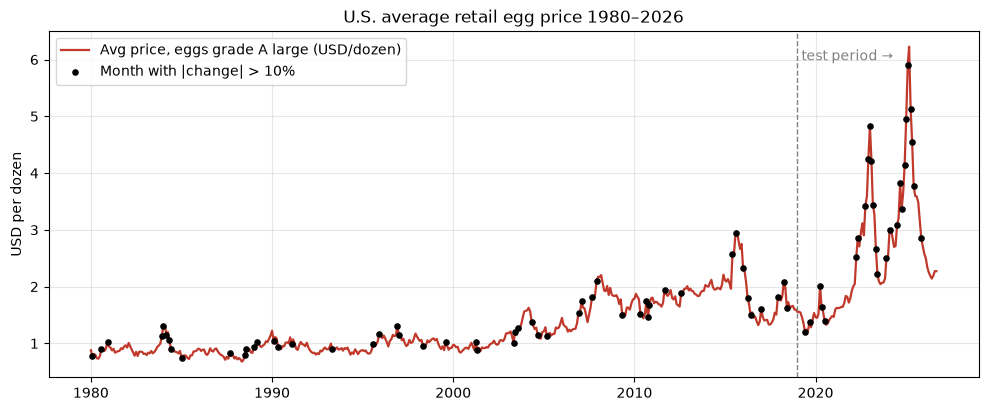

ราคาเฉลี่ยรายทศวรรษ: {1980: 0.88, 1990: 0.97, 2000: 1.33, 2010: 1.8, 2020: 2.65}
→ ราคาเฉลี่ยทศวรรษล่าสุดสูงกว่าทศวรรษ 1980 ถึง 3.0 เท่า: ข้อมูลมีเทรนด์ (non-stationary)
  โมเดลต้นไม้ทายเกินค่าที่เคยเห็นไม่ได้ จึงเปลี่ยน target เป็น "% การเปลี่ยนแปลงเดือนหน้า"


In [37]:
# 4.1 ราคาตลอดช่วง + เดือนที่ราคาเปลี่ยนแรงเกิน SPIKE
ret = np.log(price).diff()     # log-return รายเดือน ≈ % การเปลี่ยนแปลง
big = ret.abs() > SPIKE
fig, ax = plt.subplots()
ax.plot(price.index, price, color='#c0392b', lw=1.6, label='Avg price, eggs grade A large (USD/dozen)')
ax.scatter(price.index[big], price[big], s=14, color='black', zorder=3, label=f'Month with |change| > {SPIKE:.0%}')
ax.axvline(pd.Timestamp(TEST_START), color='grey', ls='--', lw=1)
ax.text(pd.Timestamp(TEST_START), ax.get_ylim()[1] * 0.95, ' test period →', color='grey', va='top')
ax.set_title('U.S. average retail egg price 1980–2026'); ax.set_ylabel('USD per dozen'); ax.legend(loc='upper left')
plt.show()

decade_mean = price.groupby((price.index.year // 10) * 10).mean()
print('ราคาเฉลี่ยรายทศวรรษ:', {int(k): round(float(v), 2) for k, v in decade_mean.items()})
print(f'→ ราคาเฉลี่ยทศวรรษล่าสุดสูงกว่าทศวรรษ 1980 ถึง {decade_mean.iloc[-1]/decade_mean.iloc[0]:.1f} เท่า: ข้อมูลมีเทรนด์ (non-stationary)')
print('  โมเดลต้นไม้ทายเกินค่าที่เคยเห็นไม่ได้ จึงเปลี่ยน target เป็น "% การเปลี่ยนแปลงเดือนหน้า"')

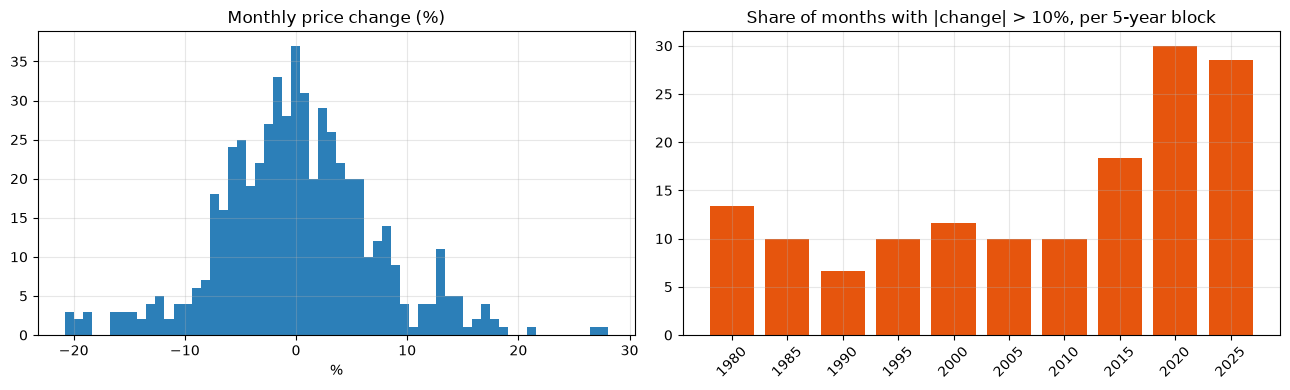

ค่า std ของการเปลี่ยนแปลงรายเดือน = 7.1%  | เดือนที่เปลี่ยนเกิน 10%: 78 จาก 560 เดือน
สัดส่วนเดือนที่เปลี่ยนแรง ต่อช่วง 5 ปี: {1980: '13%', 1985: '10%', 1990: '7%', 1995: '10%', 2000: '12%', 2005: '10%', 2010: '10%', 2015: '18%', 2020: '30%', 2025: '29%'}
→ ความผันผวนไม่เท่ากันทุกช่วง ช่วงหลัง 2015 แรงขึ้นชัดเจน ต้องแยกประเมินช่วงปกติ/ช่วงผันผวน (ขั้น 8)


In [38]:
# 4.2 การเปลี่ยนแปลงรายเดือน: รุนแรงแค่ไหน และกระจุกตัวช่วงไหน
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(ret.dropna() * 100, bins=60, color='#2c7fb8')
axes[0].set_title('Monthly price change (%)'); axes[0].set_xlabel('%')
share = big.groupby(ret.index.year // 5 * 5).mean() * 100
axes[1].bar(share.index.astype(str), share.values, color='#e6550d')
axes[1].set_title(f'Share of months with |change| > {SPIKE:.0%}, per 5-year block'); axes[1].tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

print(f'ค่า std ของการเปลี่ยนแปลงรายเดือน = {ret.std()*100:.1f}%  | เดือนที่เปลี่ยนเกิน {SPIKE:.0%}: {big.sum()} จาก {ret.notna().sum()} เดือน')
print('สัดส่วนเดือนที่เปลี่ยนแรง ต่อช่วง 5 ปี:', {int(k): f'{v:.0f}%' for k, v in share.items()})
print('→ ความผันผวนไม่เท่ากันทุกช่วง ช่วงหลัง 2015 แรงขึ้นชัดเจน ต้องแยกประเมินช่วงปกติ/ช่วงผันผวน (ขั้น 8)')

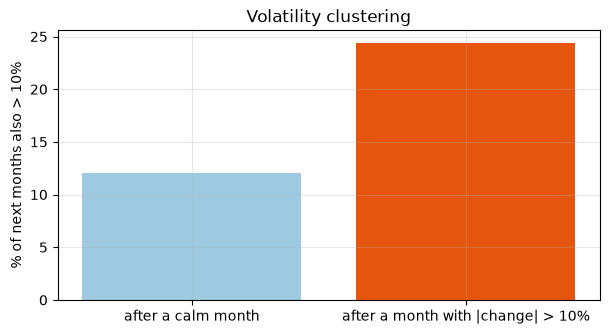

เดือนถัดจากเดือนที่เปลี่ยนแรง มีโอกาสเปลี่ยนแรงต่อ 24% vs หลังเดือนปกติ 12%
→ ความผันผวนเกาะกลุ่ม จึงใส่ feature vol_3 (ความผันผวน 3 เดือนล่าสุด) และใช้ vol_6 แบ่งช่วงปกติ/ผันผวนตอนวิเคราะห์ (ขั้น 8)


In [39]:
# 4.3 ความผันผวนเกิดเป็นกลุ่มไหม: ถ้าเดือนนี้เปลี่ยนแรง เดือนหน้ามีโอกาสเปลี่ยนแรงต่อแค่ไหน
nxt_big = big.shift(-1)
valid = ret.notna() & nxt_big.notna() & ret.shift(-1).notna()
p_after_big   = nxt_big[valid & big].astype(float).mean()
p_after_quiet = nxt_big[valid & ~big].astype(float).mean()
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(['after a calm month', f'after a month with |change| > {SPIKE:.0%}'], [p_after_quiet * 100, p_after_big * 100], color=['#9ecae1', '#e6550d'])
ax.set_ylabel('% of next months also > 10%'); ax.set_title('Volatility clustering')
plt.show()
print(f'เดือนถัดจากเดือนที่เปลี่ยนแรง มีโอกาสเปลี่ยนแรงต่อ {p_after_big:.0%} vs หลังเดือนปกติ {p_after_quiet:.0%}')
print('→ ความผันผวนเกาะกลุ่ม จึงใส่ feature vol_3 (ความผันผวน 3 เดือนล่าสุด) และใช้ vol_6 แบ่งช่วงปกติ/ผันผวนตอนวิเคราะห์ (ขั้น 8)')

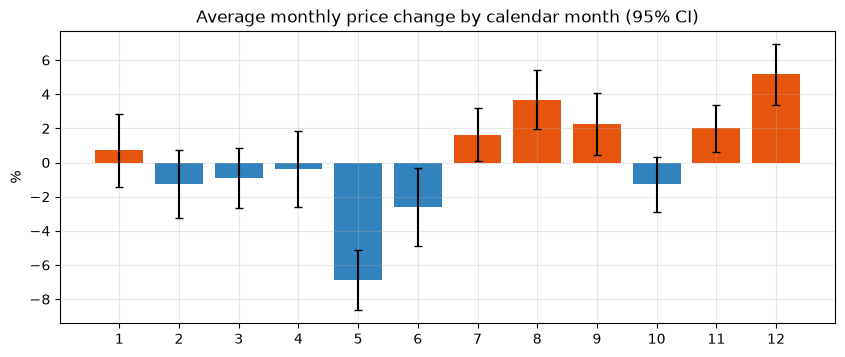

เดือนที่ค่าเฉลี่ยต่างจาก 0 อย่างมีนัยสำคัญ: {5: '-6.9%', 6: '-2.6%', 7: '+1.6%', 8: '+3.7%', 9: '+2.2%', 11: '+2.0%', 12: '+5.2%'}
→ มีรูปแบบฤดูกาลบางส่วน จึงใส่ feature month_sin / month_cos


In [40]:
# 4.4 ฤดูกาล: แต่ละเดือนของปี ราคามักขึ้นหรือลง
season = ret.groupby(ret.index.month).agg(['mean', 'std', 'count'])
se = season['std'] / np.sqrt(season['count'])
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(season.index, season['mean'] * 100, yerr=1.96 * se * 100, capsize=3,
       color=np.where(season['mean'] > 0, '#e6550d', '#3182bd'))
ax.set_xticks(range(1, 13)); ax.set_title('Average monthly price change by calendar month (95% CI)'); ax.set_ylabel('%')
plt.show()
sig = season[(season['mean'].abs() > 1.96 * se)]
print('เดือนที่ค่าเฉลี่ยต่างจาก 0 อย่างมีนัยสำคัญ:', {m: f'{v*100:+.1f}%' for m, v in sig['mean'].items()})
print('→ มีรูปแบบฤดูกาลบางส่วน จึงใส่ feature month_sin / month_cos')

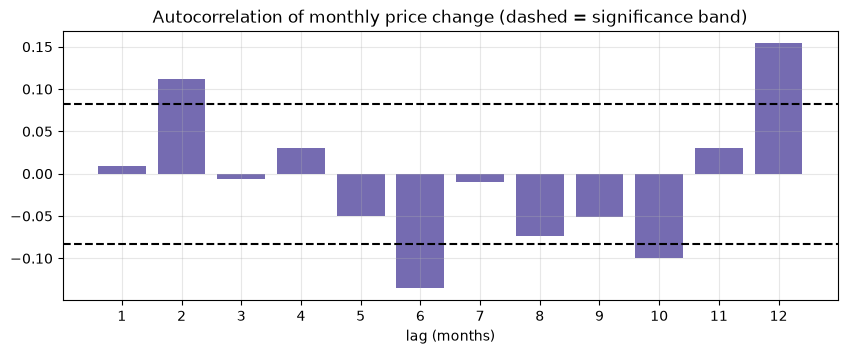

lag ที่มีนัยสำคัญ: {2: 0.11, 6: -0.14, 10: -0.1, 12: 0.15}
→ การเปลี่ยนแปลงไม่ได้สุ่มล้วน มีข้อมูลให้ใช้ทาย จึงใส่ ret_0, ret_1, ret_2 เป็น feature


In [41]:
# 4.5 Autocorrelation: การเปลี่ยนแปลงเดือนนี้ บอกเดือนถัดๆ ไปได้ไหม
lags = range(1, 13)
acf = [ret.autocorr(lag=k) for k in lags]
band = 1.96 / np.sqrt(ret.notna().sum())
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(lags, acf, color='#756bb1'); ax.axhline(band, ls='--', c='k'); ax.axhline(-band, ls='--', c='k')
ax.set_xticks(list(lags)); ax.set_title('Autocorrelation of monthly price change (dashed = significance band)'); ax.set_xlabel('lag (months)')
plt.show()
sig_lags = [k for k, a in zip(lags, acf) if abs(a) > band]
print('lag ที่มีนัยสำคัญ:', {k: round(float(acf[k-1]), 2) for k in sig_lags})
print('→ การเปลี่ยนแปลงไม่ได้สุ่มล้วน มีข้อมูลให้ใช้ทาย จึงใส่ ret_0, ret_1, ret_2 เป็น feature')

## ขั้น 5 · สร้าง features
**target** = log-return เดือนหน้า `log(price[t+1] / price[t])` แล้วแปลงกลับเป็นราคา `price[t] × exp(ทายได้)`

| feature | ความหมาย | รู้ ณ เดือน t ไหม | มาจาก EDA ข้อ |
|---|---|---|---|
| ret_0, ret_1, ret_2 | % เปลี่ยนแปลงเดือน t, t-1, t-2 | ✓ | 4.5 |
| vol_3 | ความผันผวน 3 เดือนล่าสุด | ✓ | 4.2, 4.3 |
| dev_12 | ราคาตอนนี้แพงกว่าค่าเฉลี่ย 12 เดือนแค่ไหน (ช่วยจับการ "ย่อตัว" หลังพุ่ง) | ✓ | 4.1 |
| month_sin, month_cos | เดือนของปี | ✓ | 4.4 |

In [42]:
# 5.1 ฟังก์ชันสร้าง feature (ทุกตัวใช้ข้อมูลถึงเดือน t เท่านั้น)
def make_features(price):
    r = np.log(price).diff()
    X = pd.DataFrame(index=price.index)
    X['ret_0'], X['ret_1'], X['ret_2'] = r, r.shift(1), r.shift(2)
    X['vol_3']     = r.rolling(3).std()
    X['vol_6']     = r.rolling(6).std()          # ใช้แบ่งช่วงปกติ/ผันผวนในขั้น 8 (ไม่ได้ใช้เป็น feature)
    X['dev_12']    = np.log(price / price.rolling(12).mean())
    X['month_sin'] = np.sin(2 * np.pi * price.index.month / 12)
    X['month_cos'] = np.cos(2 * np.pi * price.index.month / 12)
    X['target']    = r.shift(-1)          # สิ่งที่ต้องทาย: การเปลี่ยนแปลงเดือนหน้า
    X['price']     = price
    X['price_next']= price.shift(-1)
    return X

data = make_features(price)
FEATS = ['ret_0', 'ret_1', 'ret_2', 'vol_3', 'dev_12', 'month_sin', 'month_cos']
data[FEATS + ['target']].dropna().tail()

,ret_0,ret_1,ret_2,vol_3,dev_12,month_sin,month_cos,target
date,,,,,,,,
2026-04-01,-0.042634,-0.062727,-0.030335,0.016351,-0.326315,8.660254e-01,-0.500000,-0.026572
2026-05-01,-0.026572,-0.042634,-0.062727,0.018115,-0.287825,5.000000e-01,-0.866025,-0.023085
2026-06-01,-0.023085,-0.026572,-0.042634,0.010427,-0.263184,1.224647e-16,-1.000000,0.022172
2026-07-01,0.022172,-0.023085,-0.026572,0.027192,-0.197916,-5.000000e-01,-0.866025,0.037216
2026-08-01,0.037216,0.022172,-0.023085,0.031387,-0.118761,-8.660254e-01,-0.500000,0.000000


In [43]:
# 5.2 ตรวจ leakage แบบอัตโนมัติ: feature ทุกตัวต้องไม่สัมพันธ์กับอนาคตมากกว่าปัจจุบันแบบผิดปกติ
# วิธีง่าย: target ของแถว t ต้องเท่ากับ ret_0 ของแถว t+1 พอดี (ยืนยันว่า target คืออนาคต 1 เดือน)
check = (data['target'].shift(1) - data['ret_0']).abs().max()
print('ความต่างสูงสุดระหว่าง target[t-1] กับ ret_0[t] =', check, '→ ตรง (target คือเดือนถัดไปจริง)' if check < 1e-12 else '→ ผิด!')

ความต่างสูงสุดระหว่าง target[t-1] กับ ret_0[t] = 0.0 → ตรง (target คือเดือนถัดไปจริง)


## ขั้น 6 · ตั้งวิธีประเมิน
**Walk-forward validation:** ทุกเดือนในช่วงทดสอบ เทรนโมเดลใหม่ด้วยข้อมูล *ก่อนหน้า* เดือนนั้นเท่านั้น แล้วทาย 1 เดือนข้างหน้า เหมือนใช้งานจริงทุกเดือน (ดีกว่าแบ่ง test ก้อนเดียวเพราะโมเดลได้เห็นข้อมูลใหม่เหมือนชีวิตจริง และไม่มีทางแอบเห็นอนาคต)

**Baseline (Naive):** ราคาเดือนหน้า = ราคาเดือนนี้

In [44]:
# 6.1 walk-forward: ทุกเดือน t เทรนด้วยแถวที่ index < t (target ของแถวเหล่านั้นรู้แล้ว ณ สิ้นเดือน t)
def walk_forward(data, feats, make_model, test_idx):
    preds = {}
    for t in test_idx:
        train = data[data.index < t].dropna(subset=feats + ['target'])
        model = make_model().fit(train[feats], train['target'])
        preds[t] = model.predict(data.loc[[t], feats])[0]
    return pd.Series(preds)

MODELS = {
    'Ridge': lambda: make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    'GBM'  : lambda: GradientBoostingRegressor(n_estimators=200, max_depth=2, learning_rate=0.05,
                                               subsample=0.8, random_state=SEED),
}

In [45]:
# 6.2 ตัววัดผล
def evaluate(pred_ret, d):
    actual = d['price_next']
    pred   = d['price'] * np.exp(pred_ret)
    naive_mae = (actual - d['price']).abs().mean()
    mae  = (actual - pred).abs().mean()
    spikes = d['target'] > SPIKE
    return {
        'MAE ($/doz)' : round(mae, 3),
        'RMSE ($/doz)': round(np.sqrt(((actual - pred) ** 2).mean()), 3),
        'MASE'        : round(mae / naive_mae, 3),
        'Spike recall': f'{(pred_ret[spikes] > WARN).sum()}/{spikes.sum()}',
        'False alarms': int(((pred_ret > WARN) & ~spikes).sum()),
    }

## ขั้น 7 · สร้างโมเดลเทียบ baseline (R4)
ทุกโมเดลใช้ **ราคาย้อนหลังอย่างเดียว** ทดสอบแบบ walk-forward ตั้งแต่ `TEST_START` → เดือนล่าสุด (มีทั้งเดือนปกติและช่วงราคาพุ่ง 2022-2025)

- **Naive (baseline):** ราคาเดือนหน้า = ราคาเดือนนี้
- **Ridge:** linear regression ที่มี regularization ทาย % การเปลี่ยนแปลง
- **GBM:** Gradient Boosting ต้นไม้ตื้น ทาย % การเปลี่ยนแปลง

In [46]:
# 7.1 รัน walk-forward ทุกโมเดล
test_idx = data.index[(data.index >= TEST_START) & data['target'].notna()]
dT = data.loc[test_idx]
preds = {'Naive': pd.Series(0.0, index=test_idx)}
for name, mk in MODELS.items():
    preds[name] = walk_forward(data, FEATS, mk, test_idx)

res = pd.DataFrame({k: evaluate(v, dT) for k, v in preds.items()}).T
best = res['MASE'].astype(float).drop('Naive').idxmin()
print(f'ทดสอบ {len(test_idx)} เดือน ({test_idx[0]:%Y-%m} → {test_idx[-1]:%Y-%m}) | โมเดลดีสุด: {best}')
res

ทดสอบ 92 เดือน (2019-01 → 2026-08) | โมเดลดีสุด: GBM


,MAE ($/doz),RMSE ($/doz),MASE,Spike recall,False alarms
Naive,0.212,0.319,1.0,0/14,0
Ridge,0.212,0.32,1.002,0/14,0
GBM,0.208,0.333,0.981,0/14,1


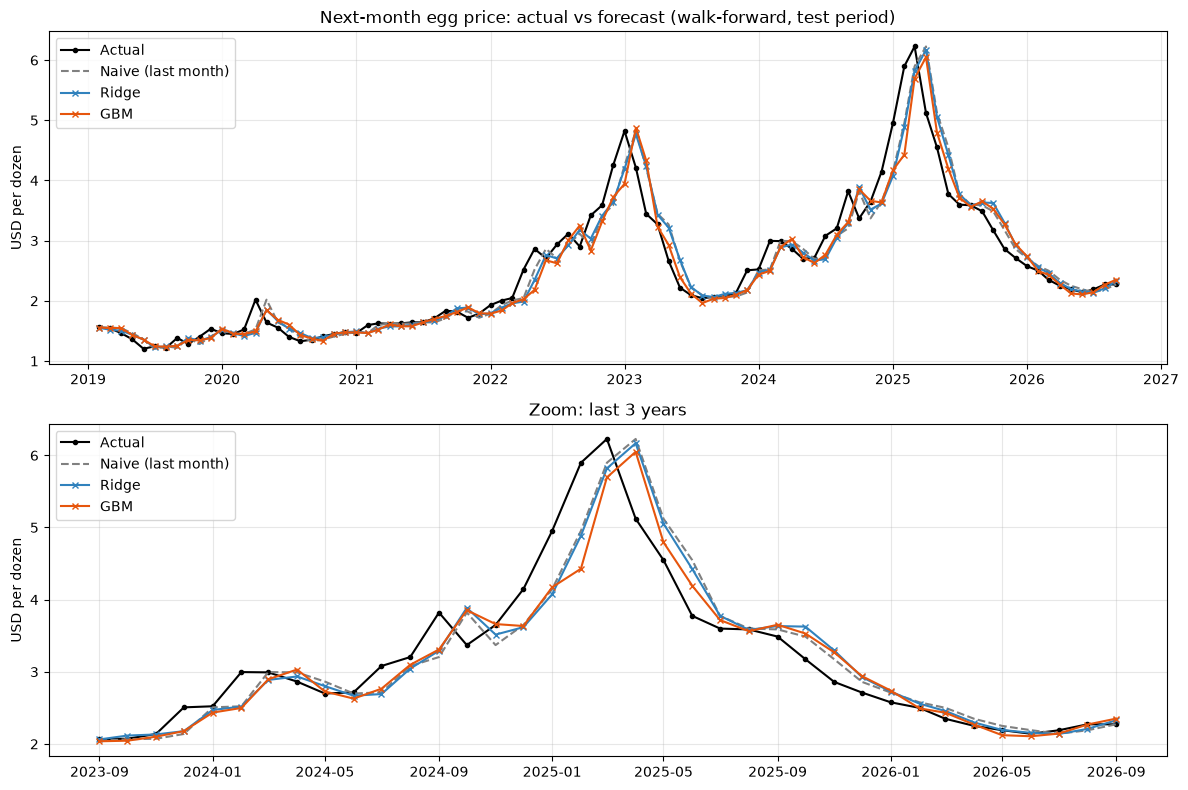

In [47]:
# 7.2 กราฟเทียบราคาจริงกับที่ทาย (ทั้งช่วงทดสอบ และซูม 3 ปีล่าสุด)
fig, axes = plt.subplots(2, 1, figsize=(12, 8))
for ax, start in zip(axes, [test_idx[0], test_idx[-1] - pd.DateOffset(months=36)]):
    d = dT[dT.index >= start]
    x = d.index + pd.offsets.MonthBegin(1)        # แสดงที่เดือน t+1 (เดือนที่ถูกทาย)
    ax.plot(x, d['price_next'], 'k-o', ms=3, label='Actual')
    ax.plot(x, d['price'], '--', c='grey', label='Naive (last month)')
    for name, c in [('Ridge', '#3182bd'), ('GBM', '#e6550d')]:
        ax.plot(x, d['price'] * np.exp(preds[name].loc[d.index]), '-x', c=c, ms=4, label=name)
    ax.set_ylabel('USD per dozen'); ax.legend(loc='upper left')
axes[0].set_title('Next-month egg price: actual vs forecast (walk-forward, test period)')
axes[1].set_title('Zoom: last 3 years')
plt.tight_layout(); plt.show()

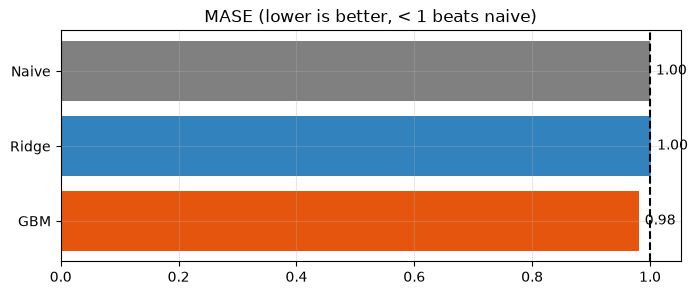

In [48]:
# 7.3 กราฟแท่ง MASE สำหรับโปสเตอร์ (ต่ำกว่า 1 = ชนะ baseline)
fig, ax = plt.subplots(figsize=(8, 3))
m = res['MASE'].astype(float)
ax.barh(m.index, m.values, color=['grey' if i == 'Naive' else ('#e6550d' if i == best else '#3182bd') for i in m.index])
ax.axvline(1, c='k', ls='--'); ax.invert_yaxis()
for i, v in enumerate(m.values): ax.text(v + 0.01, i, f'{v:.2f}', va='center')
ax.set_title('MASE (lower is better, < 1 beats naive)')
plt.show()

## ขั้น 8 · โมเดลพลาดตรงไหน (R5)

In [49]:
# 8.1 ช่วงปกติ vs ช่วงผันผวน — ผันผวน = vol_6 ณ เดือน t สูงกว่า percentile ที่ 75 ของช่วง train (รู้ได้ ณ เวลาทำนาย)
vol_cut = data.loc[data.index < TEST_START, 'vol_6'].quantile(VOL_Q)
volatile = (dT['vol_6'] > vol_cut).values
rows = {}
for name, pr in preds.items():
    err = (dT['price_next'] - dT['price'] * np.exp(pr)).abs()
    rows[name] = {'MAE normal': round(err[~volatile].mean(), 3), 'MAE volatile': round(err[volatile].mean(), 3)}
seg = pd.DataFrame(rows).T
seg['MASE normal']   = (seg['MAE normal'] / seg.loc['Naive', 'MAE normal']).round(3)
seg['MASE volatile'] = (seg['MAE volatile'] / seg.loc['Naive', 'MAE volatile']).round(3)
print(f'เกณฑ์ผันผวน: std 6 เดือน > {vol_cut*100:.1f}% | เดือนปกติ {(~volatile).sum()} เดือน | เดือนผันผวน {volatile.sum()} เดือน')
seg

เกณฑ์ผันผวน: std 6 เดือน > 7.6% | เดือนปกติ 42 เดือน | เดือนผันผวน 50 เดือน


,MAE normal,MAE volatile,MASE normal,MASE volatile
Naive,0.117,0.291,1.000,1.000
Ridge,0.119,0.290,1.017,0.997
GBM,0.117,0.284,1.000,0.976


In [50]:
# 8.2 10 เดือนที่โมเดลดีที่สุดพลาดหนักที่สุด
pr = preds[best]
err = pd.DataFrame({
    'price_t'        : dT['price'].round(2),
    'actual_next'    : dT['price_next'].round(2),
    'pred_next'      : (dT['price'] * np.exp(pr)).round(2),
    'actual_change_%': (dT['target'] * 100).round(1),
    'pred_change_%'  : (pr * 100).round(1),
})
err['abs_error'] = (err['actual_next'] - err['pred_next']).abs()
worst = err.sort_values('abs_error', ascending=False).head(10)
under = (worst['pred_next'] < worst['actual_next']).mean()
print(f'โมเดล: {best} | ใน 10 เดือนที่พลาดหนัก ทายต่ำกว่าจริง {under:.0%}')
worst

โมเดล: GBM | ใน 10 เดือนที่พลาดหนัก ทายต่ำกว่าจริง 70%


,price_t,actual_next,pred_next,actual_change_%,pred_change_%,abs_error
2025-01-01,4.95,5.90,4.43,17.4,-11.2,1.47
2025-03-01,6.23,5.12,6.05,-19.5,-2.9,0.93
2022-12-01,4.25,4.82,3.94,12.6,-7.5,0.88
2023-02-01,4.21,3.45,4.33,-20.0,2.8,0.88
2024-12-01,4.15,4.95,4.17,17.8,0.6,0.78
2022-04-01,2.52,2.86,2.18,12.8,-14.4,0.68
2023-01-01,4.82,4.21,4.88,-13.6,1.1,0.67
2022-09-01,2.90,3.42,2.83,16.4,-2.4,0.59
2025-02-01,5.90,6.23,5.69,5.4,-3.5,0.54
2020-03-01,1.52,2.02,1.49,28.1,-2.2,0.53


In [51]:
# 8.3 แบบของความผิดพลาด: แยกตามทิศทางที่ราคาจริงเปลี่ยน
direction = pd.cut(dT['target'], [-1, -SPIKE, SPIKE, 1], labels=['ราคาร่วง >10%', 'ปกติ', 'ราคาพุ่ง >10%'])
tbl = err.groupby(direction, observed=False)['abs_error'].agg(['count', 'mean']).round(3)
tbl['naive_mae'] = (dT['price_next'] - dT['price']).abs().groupby(direction, observed=False).mean().round(3)
display(tbl)
for k in tbl.index:
    verdict = 'ดีกว่า' if tbl.loc[k, 'mean'] < tbl.loc[k, 'naive_mae'] else 'แย่กว่า'
    print(f'{k}: โมเดลพลาดเฉลี่ย ${tbl.loc[k,"mean"]:.2f} vs naive ${tbl.loc[k,"naive_mae"]:.2f} → {verdict} baseline')
print('→ ใช้อธิบาย R5: เดือนที่ราคาพุ่ง/ร่วงแรงมักเกิดจากเหตุภายนอก (เช่น โรคระบาดในฟาร์ม) ซึ่งไม่มีอยู่ในข้อมูลราคาย้อนหลัง')

,count,mean,naive_mae
target,,,
ราคาร่วง >10%,12,0.419,0.528
ปกติ,66,0.089,0.088
ราคาพุ่ง >10%,14,0.589,0.521


ราคาร่วง >10%: โมเดลพลาดเฉลี่ย $0.42 vs naive $0.53 → ดีกว่า baseline
ปกติ: โมเดลพลาดเฉลี่ย $0.09 vs naive $0.09 → แย่กว่า baseline
ราคาพุ่ง >10%: โมเดลพลาดเฉลี่ย $0.59 vs naive $0.52 → แย่กว่า baseline
→ ใช้อธิบาย R5: เดือนที่ราคาพุ่ง/ร่วงแรงมักเกิดจากเหตุภายนอก (เช่น โรคระบาดในฟาร์ม) ซึ่งไม่มีอยู่ในข้อมูลราคาย้อนหลัง


In [52]:
# 8.4 ช่วงความคลาดเคลื่อนสำหรับตั้งงบ: ราคาจริงห่างจากค่าที่ทายกี่ % (จาก walk-forward)
pct_err = (dT['price_next'] / (dT['price'] * np.exp(pr)) - 1)
band = pd.DataFrame({
    'ทั้งหมด'      : pct_err.quantile([0.1, 0.9]),
    'ช่วงปกติ'     : pct_err[~volatile].quantile([0.1, 0.9]),
    'ช่วงผันผวน'   : pct_err[volatile].quantile([0.1, 0.9]),
}).T.mul(100).round(1)
band.columns = ['P10 (%)', 'P90 (%)']
display(band)
print(f'→ ช่วงปกติ: 80% ของเดือน ราคาจริงอยู่ในช่วง {band.loc["ช่วงปกติ","P10 (%)"]:+.1f}% ถึง {band.loc["ช่วงปกติ","P90 (%)"]:+.1f}% ของค่าที่ทาย')
print(f'  ช่วงผันผวน: กว้างเป็น {band.loc["ช่วงผันผวน","P10 (%)"]:+.1f}% ถึง {band.loc["ช่วงผันผวน","P90 (%)"]:+.1f}% → ฝ่ายจัดซื้อควรเผื่องบสำรองตาม P90')

,P10 (%),P90 (%)
ทั้งหมด,-10.1,15.0
ช่วงปกติ,-5.9,10.3
ช่วงผันผวน,-11.2,15.5


→ ช่วงปกติ: 80% ของเดือน ราคาจริงอยู่ในช่วง -5.9% ถึง +10.3% ของค่าที่ทาย
  ช่วงผันผวน: กว้างเป็น -11.2% ถึง +15.5% → ฝ่ายจัดซื้อควรเผื่องบสำรองตาม P90


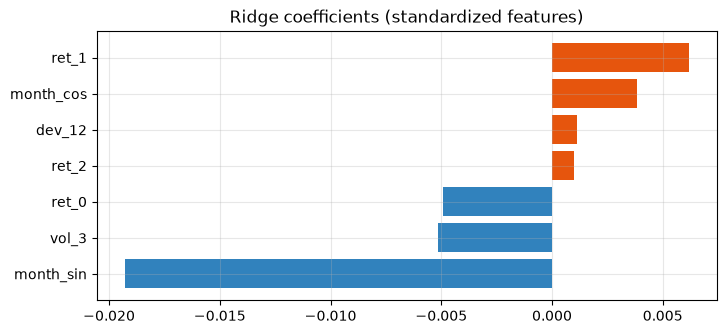

feature ที่ดันราคาเดือนหน้าขึ้นมากที่สุด: ret_1 | ดึงลงมากที่สุด: month_sin


In [53]:
# 8.5 โมเดลให้น้ำหนักอะไร: สัมประสิทธิ์ของ Ridge (เทรนด้วยข้อมูลก่อนเดือนสุดท้ายของ test)
train = data[data.index < test_idx[-1]].dropna(subset=FEATS + ['target'])
ridge = MODELS['Ridge']().fit(train[FEATS], train['target'])
coef = pd.Series(ridge[-1].coef_, index=FEATS).sort_values()
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(coef.index, coef.values, color=np.where(coef > 0, '#e6550d', '#3182bd'))
ax.set_title('Ridge coefficients (standardized features)'); plt.show()
print('feature ที่ดันราคาเดือนหน้าขึ้นมากที่สุด:', coef.idxmax(), '| ดึงลงมากที่สุด:', coef.idxmin())

## ขั้น 9 · สรุปตัวเลขสำหรับโปสเตอร์ และข้อเสนอแนะ (R6)
cell นี้ print ตัวเลขทั้งหมดที่ใช้บนโปสเตอร์ ถ้ารันใหม่แล้วตัวเลขเปลี่ยน ให้ใช้ตัวเลขจาก cell นี้

In [54]:
# 9.1 ตัวเลขสำคัญ
print('=== R2 ===')
print(f'ราคา: BLS Average Price Data (Kaggle: sadiqguru/us-bls-average-prices), series {eggs_raw["series_id"].iloc[0]}')
print(f'ใช้ {len(price)} เดือน ({price.index[0]:%Y-%m} → {price.index[-1]:%Y-%m}) จากไฟล์ดิบ {len(raw):,} แถว | เติมค่าว่าง {len(imputed_months)} เดือน')
print(f'แบ่งตามเวลา: train ก่อน {TEST_START[:7]} (ขยายทุกเดือนแบบ walk-forward) | test {len(test_idx)} เดือน')
print('=== R4 ===')
print(f'Naive MAE ${res.loc["Naive","MAE ($/doz)"]} | Ridge MAE ${res.loc["Ridge","MAE ($/doz)"]} (MASE {res.loc["Ridge","MASE"]}) | GBM MAE ${res.loc["GBM","MAE ($/doz)"]} (MASE {res.loc["GBM","MASE"]})')
print(f'โมเดลดีสุด: {best} → {"ชนะ" if float(res.loc[best,"MASE"]) < 1 else "ไม่ชนะ"} baseline')
print('=== R5 ===')
print(f'ช่วงปกติ vs ผันผวน ({best}): MAE ${seg.loc[best,"MAE normal"]} vs ${seg.loc[best,"MAE volatile"]} | MASE {seg.loc[best,"MASE normal"]} vs {seg.loc[best,"MASE volatile"]}')
print(f'Spike recall ({best}): {res.loc[best,"Spike recall"]}, false alarm {res.loc[best,"False alarms"]} ครั้ง | 10 เดือนที่พลาดหนัก ทายต่ำกว่าจริง {under:.0%}')
print('=== R6 ===')
print(f'ช่วงคลาดเคลื่อน 80% (ปกติ): {band.loc["ช่วงปกติ","P10 (%)"]:+.1f}% ถึง {band.loc["ช่วงปกติ","P90 (%)"]:+.1f}% | (ผันผวน): {band.loc["ช่วงผันผวน","P10 (%)"]:+.1f}% ถึง {band.loc["ช่วงผันผวน","P90 (%)"]:+.1f}%')

=== R2 ===
ราคา: BLS Average Price Data (Kaggle: sadiqguru/us-bls-average-prices), series APU0000708111
ใช้ 561 เดือน (1980-01 → 2026-09) จากไฟล์ดิบ 356,549 แถว | เติมค่าว่าง 1 เดือน
แบ่งตามเวลา: train ก่อน 2019-01 (ขยายทุกเดือนแบบ walk-forward) | test 92 เดือน
=== R4 ===
Naive MAE $0.212 | Ridge MAE $0.212 (MASE 1.002) | GBM MAE $0.208 (MASE 0.981)
โมเดลดีสุด: GBM → ชนะ baseline
=== R5 ===
ช่วงปกติ vs ผันผวน (GBM): MAE $0.117 vs $0.284 | MASE 1.0 vs 0.976
Spike recall (GBM): 0/14, false alarm 1 ครั้ง | 10 เดือนที่พลาดหนัก ทายต่ำกว่าจริง 70%
=== R6 ===
ช่วงคลาดเคลื่อน 80% (ปกติ): -5.9% ถึง +10.3% | (ผันผวน): -11.2% ถึง +15.5%


### 9.2 ร่างข้อเสนอแนะ (R6) — เติมตัวเลขจาก 9.1
- **ผู้ใช้ควรทำอะไร:** ตั้งงบซื้อไข่เดือนหน้า = ราคาที่ทาย × ปริมาณ และ **เผื่องบสำรองตาม P90** ของช่วงคลาดเคลื่อน ถ้าความผันผวน 6 เดือนล่าสุดสูงกว่าเกณฑ์ (ช่วงผันผวน) ให้เผื่อมากขึ้น หรือพิจารณาซื้อตุน/หาโปรตีนทดแทน
- **ต้นทุน:** ต้องอัปเดตข้อมูล BLS ทุกเดือน (ฟรี) และเทรนโมเดลใหม่ (ไม่กี่วินาที); ถ้าเผื่องบมากเกินไป เงินจะจมอยู่กับงบสำรองที่ไม่ได้ใช้
- **ข้อจำกัดที่ข้อมูลพิสูจน์ไม่ได้:** โมเดลใช้ราคาย้อนหลังอย่างเดียว จึงทายไม่ได้ว่าราคาจะ *เริ่ม* พุ่งเมื่อไร (เหตุภายนอก เช่น โรคระบาดในฟาร์ม ไม่อยู่ในข้อมูล); ข้อมูลมี ~550 เดือน (< 1,000 แถว) และช่วงวิกฤตมีน้อย; ราคาขายปลีกเฉลี่ยทั้งประเทศอาจต่างจากราคาที่ผู้ซื้อรายใหญ่จ่ายจริง; BLS ประกาศราคาช้า ~2 สัปดาห์

## ขั้น 10 · บันทึกการใช้ AI (R7)
เครื่องมือ: Claude (Claude Code) ใช้เป็นผู้ช่วยวิเคราะห์และเขียนโค้ด กลุ่มเป็นผู้ตัดสินใจและตรวจผลทุกครั้ง

| ครั้งที่ | ถาม AI ว่า | AI ตอบ/ให้อะไร | กลุ่มเปลี่ยนอะไร และเพราะอะไร |
|---|---|---|---|
| 1 | ทำไม Random Forest ทายราคาแบนอยู่ ~$4 ตอนราคาจริงพุ่งถึง $6.2 (ปี 2025) ควรทำยังไงต่อ | RF ทายเกินค่าที่เคยเห็นใน train ไม่ได้ + ราคามีเทรนด์ → ควรทาย % การเปลี่ยนแปลงแทนระดับราคา; พบบั๊ก `shift()`+`dropna()` ลบเดือน 2025-10 ถึง 2026-01 ทิ้ง; แนะนำ walk-forward + MASE | **ทำตาม** เปลี่ยน target เป็น log-return, ใช้ `asfreq`+`interpolate`, เปลี่ยนการประเมินเป็น walk-forward และวัดด้วย MASE เพราะตรวจในข้อมูลแล้วพบว่าเดือน 2025-10 ว่างจริง |
| 2 | ช่วยปรับ notebook ให้ครบ R1–R7 | AI เพิ่มข้อมูลไข้หวัดนก (USDA HPAI) ผ่าน CDC/GitHub mirror มาเป็น feature และทำการทดลองเทียบ "มี/ไม่มี HPAI" | **ไม่ทำตาม → ตัดทิ้งทั้งหมด** เพราะกลุ่มยังตรวจสอบความน่าเชื่อถือของแหล่งข้อมูลไม่ได้ (mirror บน GitHub ไม่ใช่แหล่งทางการ, ข้อมูลเริ่ม 2022 ไม่ครอบคลุมการระบาดปี 2015, ไม่รู้ license) จึงใช้แค่ BLS `average_prices` ที่ตรวจที่มาได้ |
| 3 | ตั้งโจทย์ให้ตรงการใช้งานจริง | AI ร่างผู้ใช้เป็น food bank / โครงการอาหารกลางวัน ใช้ตัดสินใจซื้อตุน | **ปรับ** เป็น "ฝ่ายจัดซื้อเสบียง ตั้งงบซื้อไข่เดือนหน้า" ให้ตรงกับโจทย์ที่กลุ่มตั้งไว้ตั้งแต่แรก และเพิ่มช่วงคลาดเคลื่อน (8.4) เพื่อใช้ตั้งงบสำรอง |
| 4 | รัน notebook ใน VS Code ไม่ได้ (ไม่มี ipykernel) | AI สร้าง `.venv` และลงแพ็กเกจที่ต้องใช้ | ใช้ตามนั้น (ไม่กระทบผลวิเคราะห์) |